In [1]:
#Import modules
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import cartopy.io.img_tiles as cimgt
import cartopy.io.shapereader as shpreader
import shapely.geometry as sgeom
from shapely.ops import unary_union
from shapely.prepared import prep
import pandas as pd
import shapely.vectorized
import geopandas as gpd
from shapely.geometry import Point
import random

In [2]:
filename = f"/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/reentry_info_2020.nc"
ds = xr.open_dataset(filename, decode_times=False)
#ds

In [3]:
pd.set_option('display.max_rows', None)
df = pd.DataFrame(
    {
        "ID":               ds["RE_ID"].values,
        "Name":             ds["RE_Name"].values,
        "Type":             ds["RE_Type"].values,
        "Burnup":           ds["RE_Burnup"].values,
        "Stage":            ds["RE_Stage"].values,
        "Lat":              ds["RE_Lat"].values,
        "Lon":              ds["RE_Lon"].values,   
        "Time":             ds["RE_Time"].values,
        "Mon":              ds["RE_Mon"].values,
        "Day":              ds["RE_Day"].values,     
        "Mass":             ds["RE_Mass"].values,
        "MCS":              ds["RE_MCS"].values,
        "Manual Location":  ds["RE_Manual_Loc"].values,
    }
)

#df.sort_values("Lon", ascending=False)

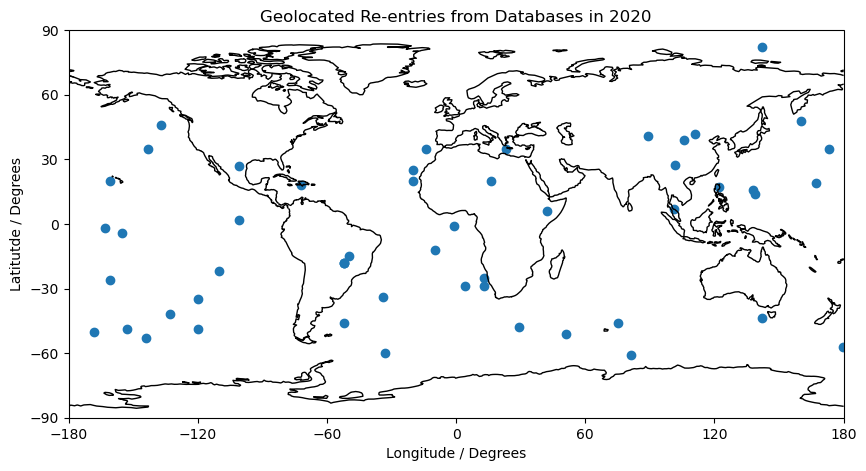

In [4]:
# First print all re-entries with location information.
# We need to base our assignment on existing relevant re-entry events (complete burnup only, not manually assigned to launch site).

df2 = df.loc[(df["Lat"] != 0) & (df["Manual Location"] == False) & (df["Burnup"] == "Complete")]
plot_array = np.array([])
for i in range(len(df2["Lat"])):
    plot_array = np.append(plot_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
                   
fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(plot_array[1::2],plot_array[::2]) 
ax.set_xlim(-180,180)
ax.set_ylim(-90,90)
ax.set_xticks(np.linspace(-180,180,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Geolocated Re-entries from Databases in 2020");

In [5]:
# Load in shapefiles for the oceans and countries, and create subspaces for individual regions.

ocean_shapefile = gpd.read_file("/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/GOaS_v1_20211214/goas_v01.shp") 
# https://www.marineregions.org/downloads.php#iho
north_pacific    = ocean_shapefile[ocean_shapefile.name.isin(['North Pacific Ocean'])]
south_pacific    = ocean_shapefile[ocean_shapefile.name.isin(['South Pacific Ocean'])]
north_atlantic   = ocean_shapefile[ocean_shapefile.name.isin(['North Atlantic Ocean'])]
south_atlantic   = ocean_shapefile[ocean_shapefile.name.isin(['South Atlantic Ocean'])]
indian_ocean     = ocean_shapefile[ocean_shapefile.name.isin(['Indian Ocean'])]
south_ocean      = ocean_shapefile[ocean_shapefile.name.isin(['Southern Ocean'])]
mediterranean    = ocean_shapefile[ocean_shapefile.name.isin(['Mediterranean Region'])]
east_asia_seas   = ocean_shapefile[ocean_shapefile.name.isin(['South China and Easter Archipelagic Seas'])] 
baltic           = ocean_shapefile[ocean_shapefile.name.isin(['Baltic Sea'])] 
arctic           = ocean_shapefile[ocean_shapefile.name.isin(['Arctic Ocean'])] 

countries_shapefile = gpd.read_file("/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp") 
north_america = countries_shapefile[countries_shapefile.NAME.isin(['Mexico'])]
south_america = countries_shapefile[countries_shapefile.NAME.isin(['Brazil'])]
east_asia     = countries_shapefile[countries_shapefile.NAME.isin(['China','Philippines'])]
africa        = countries_shapefile[countries_shapefile.NAME.isin(['Ethiopia','Chad'])]
   
# Create a function to differentiate between land or not.   
shpfilename  = shpreader.natural_earth(resolution='10m', category='physical', name='land')
reader = shpreader.Reader(shpfilename)
countries = list(reader.records())
land_geom = unary_union(
    [record.geometry
     for record in shpreader.Reader(shpfilename ).records()
     if record.attributes.get('featurecla') != "Null island"])
land = prep(land_geom)
def is_land(x, y):
   return land.contains(sgeom.Point(x, y))

52 52.0
[17.31 21.15  7.69 13.46  7.69  1.92  3.85  1.92  0.    1.92  1.92  7.69
  9.62  3.85]


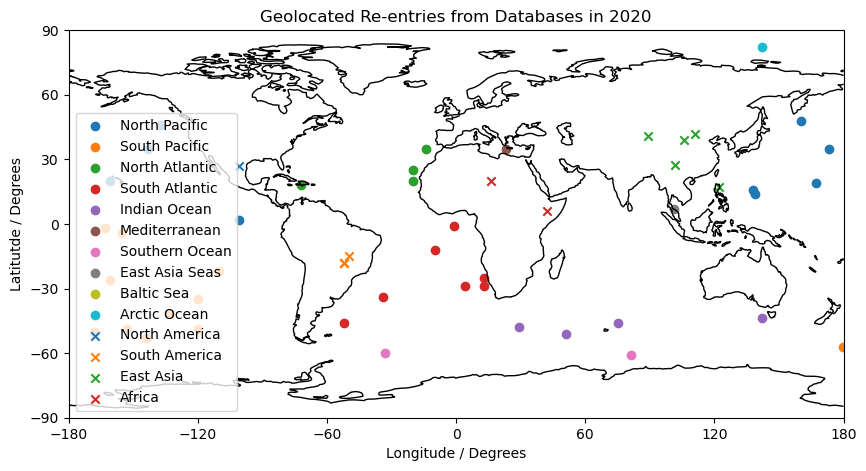

In [6]:
# Now determine in which region each existing re-entry is, and plot the remaining re-entry events.
np_array, sp_array, na_array, sa_array = np.array([]), np.array([]), np.array([]), np.array([])
io_array, so_array, med_array, eas_array = np.array([]), np.array([]), np.array([]), np.array([])
bal_array, arc_array, other_array = np.array([]), np.array([]), np.array([])
nor_am_array, sou_am_array, east_as_array, africa_array = np.array([]), np.array([]), np.array([]), np.array([])

for i in range(len(df2["Lat"])):
    coordinate = Point(df2["Lon"].values[i],df2["Lat"].values[i])
    if is_land(df2["Lon"].values[i],df2["Lat"].values[i]) != True:
        if north_pacific.geometry.contains(coordinate).any():
            np_array = np.append(np_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_pacific.geometry.contains(coordinate).any():
            sp_array = np.append(sp_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif north_atlantic.geometry.contains(coordinate).any():
            na_array = np.append(na_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_atlantic.geometry.contains(coordinate).any():
            sa_array = np.append(sa_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif indian_ocean.geometry.contains(coordinate).any():
            io_array = np.append(io_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif mediterranean.geometry.contains(coordinate).any():
            med_array = np.append(med_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_ocean.geometry.contains(coordinate).any():
            so_array = np.append(so_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif east_asia_seas.geometry.contains(coordinate).any():
            eas_array = np.append(eas_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif baltic.geometry.contains(coordinate).any():
            bal_array = np.append(bal_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif arctic.geometry.contains(coordinate).any():
            arc_array = np.append(arc_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
    else:
        if north_america.geometry.contains(coordinate).any():
            nor_am_array = np.append(nor_am_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_america.geometry.contains(coordinate).any():
            sou_am_array = np.append(sou_am_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif east_asia.geometry.contains(coordinate).any():
            east_as_array = np.append(east_as_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif africa.geometry.contains(coordinate).any():
            africa_array = np.append(africa_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0) 

weight_array = [len(np_array)/2,
                len(sp_array)/2,
                len(na_array)/2,
                len(sa_array)/2,
                len(io_array)/2,
                len(med_array)/2,
                len(so_array)/2,
                len(eas_array)/2,
                len(bal_array)/2,
                len(arc_array)/2,
                len(nor_am_array)/2,
                len(sou_am_array)/2,
                len(east_as_array)/2,
                len(africa_array)/2,
                ]

print(len(df2["Lat"]),np.sum(weight_array))
weight_array = np.round((weight_array / np.sum(weight_array) * 100) , 2)
print(weight_array)

fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(np_array[1::2],      np_array[::2], label = "North Pacific") 
ax.scatter(sp_array[1::2],      sp_array[::2], label = "South Pacific") 
ax.scatter(na_array[1::2],      na_array[::2], label = "North Atlantic") 
ax.scatter(sa_array[1::2],      sa_array[::2], label = "South Atlantic") 
ax.scatter(io_array[1::2],      io_array[::2], label = "Indian Ocean") 
ax.scatter(med_array[1::2],     med_array[::2], label = "Mediterranean") 
ax.scatter(so_array[1::2],      so_array[::2], label = "Southern Ocean") 
ax.scatter(eas_array[1::2],     eas_array[::2], label = "East Asia Seas") 
ax.scatter(bal_array[1::2],     bal_array[::2], label = "Baltic Sea") 
ax.scatter(arc_array[1::2],     arc_array[::2], label = "Arctic Ocean") 
ax.scatter(nor_am_array[1::2],  nor_am_array[::2], label = "North America", marker = 'x') 
ax.scatter(sou_am_array[1::2],  sou_am_array[::2], label = "South America", marker = 'x') 
ax.scatter(east_as_array[1::2], east_as_array[::2], label = "East Asia", marker = 'x') 
ax.scatter(africa_array[1::2],  africa_array[::2], label = "Africa", marker = 'x') 
ax.legend(loc="lower left") 
ax.set_xlim(-180,180)
ax.set_ylim(-90,90)
ax.set_xticks(np.linspace(-180,180,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Geolocated Re-entries from Databases in 2020");

In [7]:
# Randomly assign a location to each entry that is missing a geolocation tag.

def weighted_choice(weights):
    totals = []
    running_total = 0

    for w in weights:
        running_total += w
        totals.append(running_total)

    rnd = random.random() * running_total
    for i, total in enumerate(totals):
        if rnd < total:
            return i
        
region_list = [north_pacific, 
               south_pacific, 
               north_atlantic, 
               south_atlantic,  
               indian_ocean,   
               south_ocean,    
               mediterranean,   
               east_asia_seas,  
               baltic,         
               arctic,         
               north_america,       
               south_america,      
               east_asia,          
               africa            
            ]

for i in range(len(ds["RE_Lat"])):
    if ds["RE_Lon"].values[i] == 0 and ds["RE_Lat"].values[i] == 0:
        # Randomly select a region based on the existing re-entries.
        location_index = weighted_choice(weight_array)
        # Select a random lat, lon within this region and set it as the coordinates.
        random_location = region_list[location_index].sample_points(1).get_coordinates()
        ds["RE_Lon"].values[i] = random_location["x"].values[0]
        ds["RE_Lat"].values[i] = random_location["y"].values[0]
  

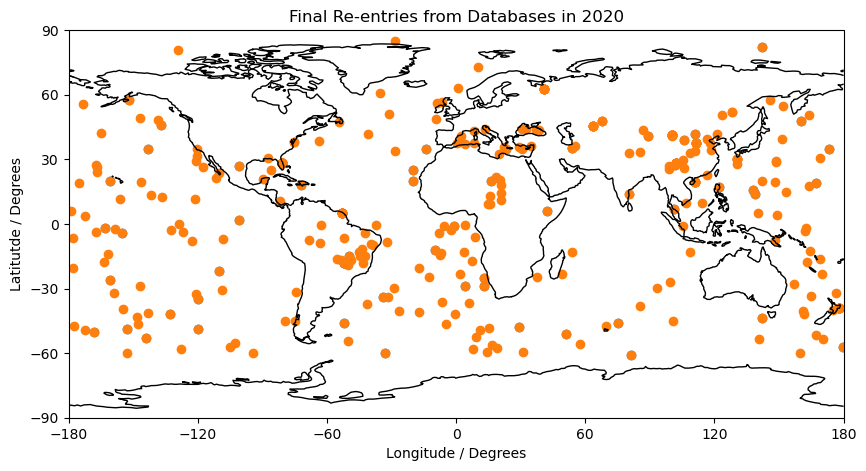

In [8]:
df_final = pd.DataFrame(
    {
        "Burnup":           ds["RE_Burnup"].values,
        "Lat":              ds["RE_Lat"].values,
        "Lon":              ds["RE_Lon"].values,  
        "Manual Location":  ds["RE_Manual_Loc"].values,
    }
)       
# Plot the final result.
#df_final = df_final.loc[(df_final["Lat"] != 0) & (df_final["Manual Location"] == False) & (df_final["Burnup"] == "Complete")]
plot_array_final = np.array([])
for i in range(len(df_final["Lat"])):
    plot_array_final = np.append(plot_array_final, [df_final["Lat"].values[i], df_final["Lon"].values[i]], axis=0)
                   
fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(plot_array[1::2],plot_array[::2])             # From original database geolocated re-entries plot
ax.scatter(plot_array_final[1::2],plot_array_final[::2]) # Final re-entries after added lat/lon data
ax.set_xlim(-180,180)
ax.set_ylim(-90,90)
ax.set_xticks(np.linspace(-180,180,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Final Re-entries from Databases in 2020");

In [10]:
pd.set_option('display.max_rows', None)
df_print = pd.DataFrame(
    {
        "ID":               ds["RE_ID"].values,
        "Name":             ds["RE_Name"].values,
        "Type":             ds["RE_Type"].values,
        "Burnup":           ds["RE_Burnup"].values,
        "Stage":            ds["RE_Stage"].values,
        "Lat":              ds["RE_Lat"].values,
        "Lon":              ds["RE_Lon"].values,   
        "Time":             ds["RE_Time"].values,
        "Mon":              ds["RE_Mon"].values,
        "Day":              ds["RE_Day"].values,     
        "Mass":             ds["RE_Mass"].values,
        "MCS":              ds["RE_MCS"].values,
        "Manual Location":  ds["RE_Manual_Loc"].values,
    }
)

df_print.sort_values("Mass", ascending=True)

,ID,Name,Type,Burnup,Stage,Lat,Lon,Time,Mon,Day,Mass,MCS,Manual Location
3,1986-014D,USA-17 cover?,Component,Complete,5,48.361418,-138.278053,0.000000,12,07,0.000,False,False
4,1963-014EZ,West Ford dipoles,Component,Complete,5,-36.174094,-6.792886,0.000000,11,08,0.000,False,False
6,1997-012B,DMSP F-14 solar array band?,Component,Complete,5,29.482273,148.643336,0.000000,10,26,0.000,False,False
48,2018-056J,PRSS/PakTES debris,Component,Complete,5,-9.462777,-39.766263,0.000000,01,12,0.000,False,False
109,2019-059E,deb CZ-4B?,Component,Complete,5,-14.934646,-44.538775,0.000000,07,29,0.000,False,False
197,2020-067E,CZ-4B sep motor cover,Component,Complete,5,27.093296,98.806730,0.000000,11,17,0.000,False,False
38,2018-021D,H-2A F38 adapter?,Component,Complete,5,-6.817893,-108.243176,0.000000,01,10,0.000,False,False
142,2019-022L,Gangestad,Payload,Complete,5,-31.520588,-74.397518,0.000000,08,07,0.016,False,False
108,2019-022J,Venturini,Payload,Complete,5,-41.861954,-0.421816,0.000000,02,12,0.016,False,False
160,2019-022M,Fuller,Payload,Complete,5,55.030414,151.732747,0.000000,10,15,0.016,False,False


In [11]:
#Save to file and close the DataSet     
#ds.to_netcdf(f'./Databases/reentry_info_2020_updated.nc')
ds.close()